# HW4 — Monthly volatility and RSI feature experiment
**Author:** Mauricio Gutierrez

Test whether two additional price features improve the existing Ridge strategy.
Keep the five baseline features. Add monthly volatility and RSI. Investigate
P/S separately before using it. Preserve the outputs of notebooks 02 and 03.

```text
Cleaned class data -> Same baseline features and targets
                                    |
                         +----------+----------+
                         |                     |
                         v                     v
                 Baseline Ridge      Ridge + monthly volatility + RSI
                         |                     |
                         v                     v
                 Same monthly trading rules and fees
                                    |
                                    v
                   Compare NAV, returns, Sharpe, and drawdown
```

This is a controlled **2013–2015 development comparison**, not a final-test run.
It tests the two added features together. It does not identify each feature's
individual effect. No alpha search or trading-rule change is performed.

> **Development step, class data (30 stocks).** Rejected experiment: 21-session volatility and RSI did not improve the ranking. The final strategy is defined in `run_final_test.py` and reported in `07_final_test_report.ipynb`.

## Run instructions
1. Run notebook 01 if the cleaned class database is missing.
2. Run notebook 02 to save the baseline model settings and forecasts.
3. Run notebook 03 to save the baseline strategy settings and results.
4. Open `04b_feature_experiment.ipynb` with the course `.venv` kernel.
5. Select **Restart Kernel and Run All Cells**.
6. Read the comparison and the conclusion below.

The run order is **01 -> 02 -> 03 -> 04**. Existing baseline files can be reused.
Notebook 04 fits both model versions and runs both portfolios. It checks that
the reproduced baseline matches the saved baseline. It saves its own outputs
under `outputs/feature_experiments/monthly_volatility_rsi/`.

For changes to these additional feature functions, restart and rerun notebook 04.
For a baseline feature, model, cleaning, or strategy change, rerun the affected
earlier notebooks first. Do not run cells out of order.

In [1]:
from pathlib import Path
from dataclasses import asdict
import sys
import io
import json
import hashlib
import unittest

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "Lectures/modeling/course_data.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Start the kernel inside the course repository.")
HW_DIR = ROOT / "Homeworks/HW4/Mauricio_Gutierrez"
if str(HW_DIR) not in sys.path:
    sys.path.insert(0, str(HW_DIR))
from feature_engineering import (
    PRICE_FEATURES, ADDITIONAL_PRICE_FEATURES, load_cleaned_data, price_features,
    additional_price_features, apply_membership, make_labels, annual_split,
    make_ridge_pipeline, prediction_metrics, price_to_sales,
)
from strategy_backtest import BacktestConfig, Backtester, compare_performance

## 1. Keep the comparison settings fixed
Read the baseline settings from the saved experiment. Use the same annual
training splits, Ridge alpha, 90-day target, eligible stocks, and trading rules.
Only the model's input columns change.

Baseline trading rules: five ranked stocks, monthly decisions, one-third-NAV
cash budget, equal allocations, 30% stock limit, 50% sector limit, and 90-day
exits. Entry and exit fees remain 0.10% per side in the saved baseline.

In [ ]:
DATABASE = HW_DIR / "outputs/data_cleaning/equities_class/equities_class_cleaned.duckdb"
MODEL_DIR = HW_DIR / "outputs/ridge_baseline/equities_class"
BASELINE_DIR = HW_DIR / "outputs/backtesting/ridge_monthly_baseline"
OUTPUT_DIR = HW_DIR / "outputs/feature_experiments/monthly_volatility_rsi"
SAVE_OUTPUTS = True
required = [DATABASE, MODEL_DIR / "experiment.json", MODEL_DIR / "validation_forecasts.csv",
            BASELINE_DIR / "experiment.json", BASELINE_DIR / "performance.csv"]
for path in required:
    if not path.is_file():
        raise FileNotFoundError(f"Run notebooks 01, 02, and 03 first. Missing: {path}")

def digest(path):
    with path.open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()

protected_files = [DATABASE, *MODEL_DIR.glob("*.*"), *BASELINE_DIR.glob("*.*")]
protected_hashes = {path: digest(path) for path in protected_files if path.is_file()}
model_settings = json.loads((MODEL_DIR / "experiment.json").read_text(encoding="utf-8"))
baseline_settings = json.loads((BASELINE_DIR / "experiment.json").read_text(encoding="utf-8"))
assert digest(DATABASE) == model_settings["database_sha256"] == baseline_settings["database_sha256"]
assert digest(MODEL_DIR / "validation_forecasts.csv") == baseline_settings["forecasts_sha256"]
if digest(HW_DIR / "strategy_backtest.py") != baseline_settings["backtester_sha256"]:
    print("The shared engine changed. The saved-baseline reproduction checks below must still pass.")
assert baseline_settings["model_settings"] == model_settings
CONFIG = BacktestConfig(**baseline_settings["config"])
START, END = baseline_settings["start"], baseline_settings["end"]
assert pd.Timestamp(END) <= pd.Timestamp("2015-12-31"), "Keep the final test closed."
assert CONFIG.holding_days == model_settings["holding_calendar_days"]
BASELINE_FEATURES = model_settings["features"]
EXPANDED_FEATURES = BASELINE_FEATURES + ADDITIONAL_PRICE_FEATURES
FEATURE_SETS = {"Baseline Ridge": BASELINE_FEATURES, "Ridge + volatility + RSI": EXPANDED_FEATURES}
display(pd.DataFrame({"Model": list(FEATURE_SETS),
                      "Features": [", ".join(v) for v in FEATURE_SETS.values()]}))

## 2. Define the requested features
The functions are in `feature_engineering.py`. They use only prices known by
the signal close. Reindex prices to market sessions and leave gaps missing.

| Requested feature | Function / model column | Definition |
|---|---|---|
| Monthly volatility | `monthly_volatility` / `volatility_monthly_21` | Sample standard deviation of the last 21 daily simple returns times square root of 21 |
| RSI | `relative_strength_index` / `rsi_14` | 14-session Wilder RSI from adjusted-close changes, on a 0–100 scale |
| P/S | `price_to_sales` | Verified market capitalization divided by trailing twelve-month sales; not enabled with the current class data |

Monthly volatility is a rolling one-month estimate in decimal monthly units.
It differs from the existing `volatility_63`, which uses 63 returns and annual
scaling. For example, monthly volatility of `0.10` means 10%, not 10% return.

RSI starts with the mean gains and losses from 14 changes. Each later average
uses Wilder's update: `(13 * previous average + new gain or loss) / 14`.
A rising series without losses has RSI 100. A falling series without gains has
RSI 0. This implementation assigns RSI 50 to a flat series. It resets the
calculation after a missing session. No RSI threshold forces a trade.

See the [RSI formula](https://www.tradingview.com/support/solutions/43000502338-relative-strength-index-rsi/)
and the [P/S definition](https://scs.fidelity.com/webcontent/ap010098-etf-content/17.02/help/research/learn_er_glossary_3.shtml).

## 3. Check whether P/S is usable
P/S needs comparable monetary units, matching currencies, and a valid market
capitalization. Its denominator is **twelve-month sales**, not one quarter's
revenue. Every report used in that denominator must be available at the signal
date. An annual sales total must not use a future filing.

The class dataset has quarterly revenue, but most currency labels are missing.
Its market-cap field is also sparse. The course data guide warns about price
and share-count adjustment and unit mismatches. Multiplying adjusted close by
reported shares would not resolve those problems.

The audit below checks basic prerequisites. It does not certify market-cap
currency, units, or historical timing. We exclude P/S from this experiment.
The documented `price_to_sales` arithmetic function is ready for verified,
time-aligned market-cap and trailing-sales Series. It does not create TTM sales
or perform publication-date joins. Do not interpret its presence as a usable
P/S dataset. See the [data guide](../../../Lectures/modeling/README.md).

In [3]:
prices, calendar, membership = load_cleaned_data(DATABASE, end=model_settings["data_end"])
with duckdb.connect(str(DATABASE), read_only=True) as connection:
    financials = connection.execute(
        "SELECT symbol, fiscal_date, filing_date, available_date, revenue, market_cap, reported_currency FROM fundamentals WHERE available_date <= ?",
        [model_settings["data_end"]],
    ).fetchdf()
    universe = connection.execute("SELECT symbol, sector FROM universe").fetchdf()
    benchmark = connection.execute(
        "SELECT date, adj_close FROM benchmark WHERE symbol = '^SP500TR' AND date <= ? ORDER BY date", [END]
    ).fetchdf()
sectors = universe.set_index("symbol").sector.to_dict()
benchmark["date"] = pd.to_datetime(benchmark.date).astype("datetime64[ns]")
known_currency = financials.reported_currency.notna() & financials.reported_currency.fillna("").str.strip().ne("")
positive_cap = financials.market_cap.gt(0) & np.isfinite(financials.market_cap)
positive_sales = financials.revenue.gt(0) & np.isfinite(financials.revenue)
ps_audit = pd.Series({
    "reports_available_by_cutoff": len(financials),
    "reports_without_currency": int((~known_currency).sum()),
    "reports_with_positive_market_cap": int(positive_cap.sum()),
    "reports_with_currency_and_positive_cap_and_quarter_sales": int((known_currency & positive_cap & positive_sales).sum()),
}, name="P/S input audit")
display(ps_audit.to_frame())
print("P/S excluded: the current data does not provide verified, time-aligned P/S inputs.")

P/S excluded: the current data does not provide verified, time-aligned P/S inputs.


,P/S input audit
reports_available_by_cutoff,1045
reports_without_currency,1044
reports_with_positive_market_cap,78
reports_with_currency_and_positive_cap_and_quarter_sales,0


## 4. Build one shared panel
Add the two new columns to the original panel. Keep baseline eligibility and
return targets unchanged. The additional feature values do not remove stocks.
The model pipeline learns clipping, imputation, and scaling from training rows.

Read the coverage table before fitting. A feature that is always missing cannot
add information. P/S is excluded explicitly rather than filled with an invented
value. Longer-window missing baseline features follow the existing imputation rule.

In [4]:
base = apply_membership(price_features(prices, calendar), membership, calendar)
extra = additional_price_features(prices, calendar)
panel = base.merge(extra, on=["date", "symbol"], how="left", validate="one_to_one")
panel = make_labels(panel, prices, calendar, holding_days=CONFIG.holding_days,
                    max_exit_delay=model_settings["max_exit_delay_sessions"])
eligible = panel.loc[panel.eligible & panel.date.ge(model_settings["train_start"])]
coverage = pd.DataFrame({"observed_rows": eligible[EXPANDED_FEATURES].notna().sum(),
                         "missing_percent": eligible[EXPANDED_FEATURES].isna().mean() * 100})
display(coverage)
display(eligible[["date", "symbol", *ADDITIONAL_PRICE_FEATURES]].head())
assert eligible[ADDITIONAL_PRICE_FEATURES].notna().any().all()

suite = unittest.defaultTestLoader.discover(str(HW_DIR), pattern="test_*.py")
test_log = io.StringIO()
test_result = unittest.TextTestRunner(stream=test_log, verbosity=1).run(suite)
print(test_log.getvalue())
assert test_result.wasSuccessful()

.......................
----------------------------------------------------------------------
Ran 23 tests in 0.599s

OK



,observed_rows,missing_percent
momentum_21,43381,0.0
momentum_63,43381,0.0
momentum_252_21,43381,0.0
volatility_63,43381,0.0
drawdown_252,43381,0.0
volatility_monthly_21,43381,0.0
rsi_14,43381,0.0


,date,symbol,volatility_monthly_21,rsi_14
14901,2010-01-04,AAPL,0.076491,66.983036
14902,2010-01-04,AMT,0.053800,68.908946
14903,2010-01-04,APDN,0.368880,44.594219
14904,2010-01-04,BESS,0.698540,46.273903
14905,2010-01-04,BKNG,0.075933,58.634489


## 5. Fit both Ridge versions on identical dates
Use the baseline's alpha and annual split years. Before each fit, require each
training target to have ended. Forecast every eligible validation row, including
rows whose future returns are unknown. Future target columns never enter `X`.

Reproduce the saved baseline predictions as a check. If that check fails, stop
and inspect the changed baseline inputs before claiming a feature improvement.

In [5]:
forecasts_by_model = {}
model_score_rows = []
split_rows = []
for year in model_settings["validation_years"]:
    train, signals = annual_split(panel, year, train_start=model_settings["train_start"])
    assert train.label_end.max() < signals.date.min()
    split_rows.append({"year": year, "training_rows": len(train), "forecast_rows": len(signals),
                       "last_training_outcome": train.label_end.max(), "first_signal": signals.date.min()})
    for name, feature_names in FEATURE_SETS.items():
        model = make_ridge_pipeline(alpha=model_settings["alpha"], feature_names=feature_names)
        model.fit(train[feature_names], train.target)
        forecast = signals[["date", "symbol", "target", "label_end"]].copy()
        forecast["prediction"] = model.predict(signals[feature_names])
        forecast["validation_year"] = year
        forecasts_by_model.setdefault(name, []).append(forecast)
        scored = forecast.loc[forecast.target.notna()]
        model_score_rows.append({"model": name, "year": year,
                                 **prediction_metrics(scored, scored.prediction).to_dict()})
forecasts_by_model = {name: pd.concat(parts, ignore_index=True) for name, parts in forecasts_by_model.items()}
splits = pd.DataFrame(split_rows)
model_scores = pd.DataFrame(model_score_rows)
display(splits)
display(model_scores.round(4))

saved_baseline = pd.read_csv(MODEL_DIR / "validation_forecasts.csv", parse_dates=["date"])
baseline_check = forecasts_by_model["Baseline Ridge"].merge(
    saved_baseline[["date", "symbol", "prediction"]], on=["date", "symbol"],
    suffixes=("_new", "_saved"), how="outer", validate="one_to_one", indicator=True,
)
assert baseline_check._merge.eq("both").all()
np.testing.assert_allclose(baseline_check.prediction_new, baseline_check.prediction_saved, rtol=1e-10, atol=1e-10)
print("PASS: baseline predictions match notebook 02.")

PASS: baseline predictions match notebook 02.


,year,training_rows,forecast_rows,last_training_outcome,first_signal
0,2013,20034,7308,2012-12-31,2013-01-02
1,2014,27284,7243,2013-12-31,2014-01-02
2,2015,34590,7027,2014-12-31,2015-01-02


,model,year,RMSE,MAE,R2,mean_daily_rank_IC,IC_dates
0,Baseline Ridge,2013,0.1374,0.0915,0.0891,0.0092,252.0
1,Ridge + volatility + RSI,2013,0.1368,0.0914,0.0978,-0.0000,252.0
2,Baseline Ridge,2014,0.1528,0.0950,-0.1949,-0.0500,252.0
3,Ridge + volatility + RSI,2014,0.1532,0.0953,-0.2005,-0.0439,252.0
4,Baseline Ridge,2015,0.1846,0.1135,0.0023,0.2043,189.0
5,Ridge + volatility + RSI,2015,0.1836,0.1124,0.0136,0.2016,189.0


## 6. Run the same trading strategy for both models
Keep cash allocation, fees, limits, monthly sessions, and exit timing fixed.
Use the original backtester. Do not tune a trading rule after seeing this result.

The benchmark uses the same dates. Final value includes open positions. Sharpe
is annualized from daily excess returns with the baseline's 2% risk-free rate.
Cash still earns zero. Reconcile both accounts before comparing the results.

In [6]:
results = {}
equity_curves = pd.DataFrame()
performance_parts = []
diagnostics = []
for name, forecasts in forecasts_by_model.items():
    result = Backtester(CONFIG).run(prices, calendar, forecasts[["date", "symbol", "prediction"]],
                                    sectors, membership, START, END)
    curves, perf = compare_performance(result.daily, benchmark, CONFIG)
    results[name] = result
    equity_curves[name] = curves.Strategy
    performance_parts.append(perf.loc[["Strategy"]].rename(index={"Strategy": name}))
    flows = result.trades.groupby("date").cash_change.sum().reindex(result.daily.date, fill_value=0.0) if not result.trades.empty else pd.Series(0.0, index=result.daily.date)
    np.testing.assert_allclose(result.daily.cash, CONFIG.initial_cash + flows.cumsum(), atol=1e-6)
    np.testing.assert_allclose(result.daily.nav, result.daily.cash + result.daily.holdings_value, atol=1e-6)
    final_open = result.open_lots.market_value.sum()
    assert np.isclose(result.daily.nav.iloc[-1], result.daily.cash.iloc[-1] + final_open)
    sold = result.trades.loc[result.trades.side.eq("SELL")]
    for row in sold.itertuples():
        assert row.date == calendar[calendar.searchsorted(row.due_date)]
    diagnostics.append({"model": name, "buy_trades": int(result.trades.side.eq("BUY").sum()),
                        "sell_trades": len(sold), "fees": result.daily.fees.sum(),
                        "skipped_months": int(result.decisions.reason.ne("planned").sum()),
                        "average_cash_weight": (result.daily.cash / result.daily.nav).mean(),
                        "exposure_breach_sessions": int(result.daily.exposure_breach.sum())})
equity_curves["S&P 500 TR"] = curves["S&P 500 TR"]
performance_parts.append(perf.loc[["S&P 500 TR"]])
performance = pd.concat(performance_parts)
diagnostics = pd.DataFrame(diagnostics).set_index("model")
saved_performance = pd.read_csv(BASELINE_DIR / "performance.csv", index_col="portfolio")
np.testing.assert_allclose(performance.loc["Baseline Ridge"], saved_performance.loc["Strategy"], rtol=1e-10, atol=1e-8)
print("PASS: baseline portfolio results match notebook 03; both accounts reconcile.")

formatted = performance.copy()
for column, pattern in {"final_value": "${:,.2f}", "total_return": "{:.2%}", "CAGR": "{:.2%}",
                         "max_drawdown": "{:.2%}", "daily_Sharpe": "{:.3f}"}.items():
    formatted[column] = performance[column].map(pattern.format)
display(formatted)
display(diagnostics.round(4))

PASS: baseline portfolio results match notebook 03; both accounts reconcile.


,final_value,total_return,CAGR,max_drawdown,daily_Sharpe
portfolio,,,,,
Baseline Ridge,"$1,249,845.83",24.98%,7.74%,-29.39%,0.332
Ridge + volatility + RSI,"$1,322,879.91",32.29%,9.80%,-29.94%,0.391
S&P 500 TR,"$1,487,843.34",48.78%,14.20%,-12.04%,0.950


,buy_trades,sell_trades,fees,skipped_months,average_cash_weight,exposure_breach_sessions
model,,,,,,
Baseline Ridge,165,155,24502.9775,3,0.1833,0
Ridge + volatility + RSI,160,150,25222.4685,4,0.1815,3


## 7. Compare monthly NAV and daily drawdown
Take the last observed session in each month for monthly NAV. Do not average
the daily account values. Compute drawdown from daily values so an intramonth
loss is not hidden by month-end sampling.

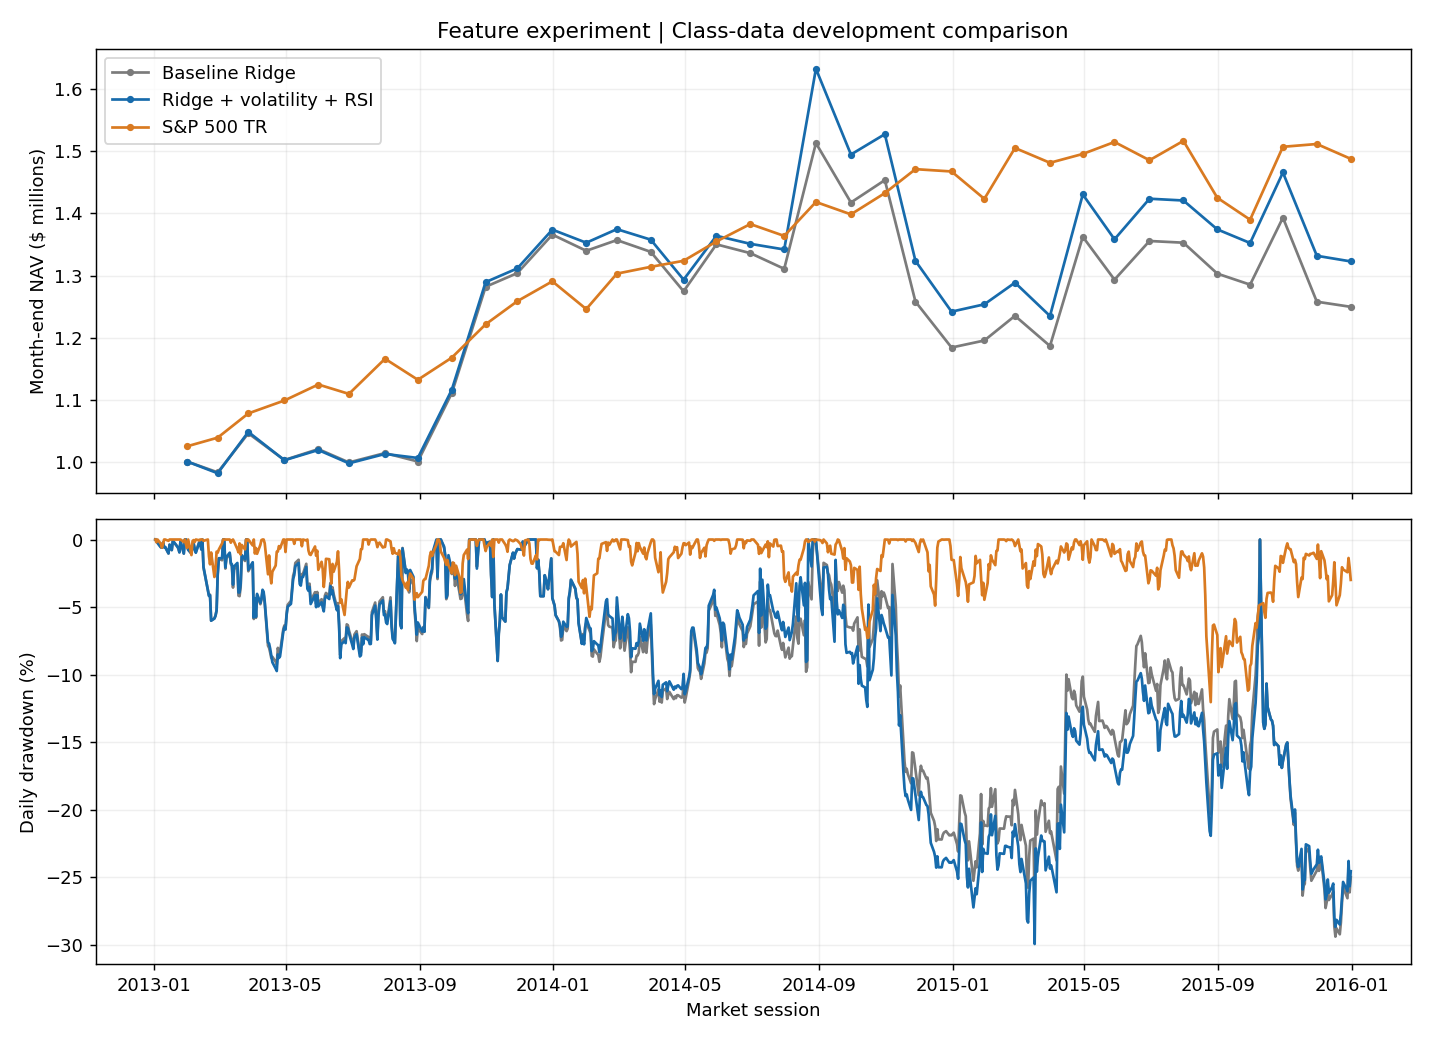

In [7]:
monthly_nav = equity_curves.groupby(equity_curves.index.to_period("M")).tail(1)
monthly_nav.index.name = "month_end_session"
assert len(monthly_nav) == equity_curves.index.to_period("M").nunique()
np.testing.assert_allclose(monthly_nav.iloc[-1], equity_curves.iloc[-1])
fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
for (name, nav), color in zip(equity_curves.items(), ["#7b7b7b", "#176bac", "#d97a21"]):
    axes[0].plot(monthly_nav.index, monthly_nav[name] / 1_000_000, marker="o", markersize=3,
                 label=name, color=color)
    axes[1].plot(nav.index, (nav / nav.cummax() - 1) * 100, color=color)
axes[0].set(title="Feature experiment | Class-data development comparison", ylabel="Month-end NAV ($ millions)")
axes[0].legend(loc="upper left")
axes[1].set(ylabel="Daily drawdown (%)", xlabel="Market session")
for ax in axes:
    ax.grid(alpha=0.2)
fig.tight_layout()
buffer = io.BytesIO()
fig.savefig(buffer, format="png", dpi=130)
comparison_png = buffer.getvalue()
display(Image(data=comparison_png))
plt.close(fig)

## 8. Answer the experiment question
Read return, Sharpe, and drawdown together. A change in prediction RMSE alone
does not answer whether the portfolio improved. The interpretation below uses
the computed results. It updates when this experiment runs again.

In [8]:
old = performance.loc["Baseline Ridge"]
new = performance.loc["Ridge + volatility + RSI"]
benchmark_result = performance.loc["S&P 500 TR"]
return_change = new.total_return - old.total_return
sharpe_change = new.daily_Sharpe - old.daily_Sharpe
return_verdict = "improved" if return_change > 0 else "decreased" if return_change < 0 else "did not change"
sharpe_verdict = "improved" if sharpe_change > 0 else "decreased" if sharpe_change < 0 else "did not change"
analysis_text = f"""### Result of adding monthly volatility and RSI

**Return {return_verdict}.** Baseline total return was **{old.total_return:.2%}**.
The expanded model returned **{new.total_return:.2%}**. The change was
**{return_change * 100:+.2f} percentage points**, or **${new.final_value - old.final_value:+,.2f}**
in final account value. Expanded-model CAGR was **{new.CAGR:.2%}**.

**Sharpe {sharpe_verdict}.** The annualized Sharpe from daily returns moved from
**{old.daily_Sharpe:.3f}** to **{new.daily_Sharpe:.3f}**, a change of **{sharpe_change:+.3f}**.
The risk-free rate, trading rules, fees, and evaluation dates are identical.

**Risk and benchmark.** Maximum drawdown changed from **{old.max_drawdown:.2%}** to
**{new.max_drawdown:.2%}**. The benchmark returned **{benchmark_result.total_return:.2%}**
with Sharpe **{benchmark_result.daily_Sharpe:.3f}**. Inspect the chart and trade
diagnostics before deciding whether to keep the added features.

**Exposure checks.** The expanded account had
**{int(diagnostics.loc["Ridge + volatility + RSI", "exposure_breach_sessions"])} sessions**
with a stock or sector weight above its limit after price moves. Orders still
use the original signal-close limits. The engine records later breaches and
keeps the 90-day exit rule. Inspect the daily log before interpreting the risk.

**P/S was not tested.** The database does not provide verified currency-, unit-,
and date-aligned inputs. The P/S helper is documented for future verified data.
These results test monthly volatility and RSI together, not P/S and not each
new feature separately.

**Interpretation limit.** This is one development comparison on the small class
dataset. It does not establish a reliable improvement on unseen data. The
baseline remains saved. The full-dataset final test remains closed.
"""
display(Markdown(analysis_text))

### Result of adding monthly volatility and RSI

**Return improved.** Baseline total return was **24.98%**.
The expanded model returned **32.29%**. The change was
**+7.30 percentage points**, or **$+73,034.09**
in final account value. Expanded-model CAGR was **9.80%**.

**Sharpe improved.** The annualized Sharpe from daily returns moved from
**0.332** to **0.391**, a change of **+0.060**.
The risk-free rate, trading rules, fees, and evaluation dates are identical.

**Risk and benchmark.** Maximum drawdown changed from **-29.39%** to
**-29.94%**. The benchmark returned **48.78%**
with Sharpe **0.950**. Inspect the chart and trade
diagnostics before deciding whether to keep the added features.

**Exposure checks.** The expanded account had
**3 sessions**
with a stock or sector weight above its limit after price moves. Orders still
use the original signal-close limits. The engine records later breaches and
keeps the 90-day exit rule. Inspect the daily log before interpreting the risk.

**P/S was not tested.** The database does not provide verified currency-, unit-,
and date-aligned inputs. The P/S helper is documented for future verified data.
These results test monthly volatility and RSI together, not P/S and not each
new feature separately.

**Interpretation limit.** This is one development comparison on the small class
dataset. It does not establish a reliable improvement on unseen data. The
baseline remains saved. The full-dataset final test remains closed.


## 9. Save this experiment separately
Save the feature coverage, P/S audit, forecasts, split dates, model scores,
portfolio comparisons, monthly NAV, chart, written analysis, and each account's
trade records. Keep all baseline files unchanged. All generated outputs are
ignored by Git. Reusing this experiment folder overwrites this run's files.

In [9]:
assert all(digest(path) == checksum for path, checksum in protected_hashes.items())
if SAVE_OUTPUTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    coverage.to_csv(OUTPUT_DIR / "feature_coverage.csv")
    ps_audit.to_csv(OUTPUT_DIR / "ps_input_audit.csv")
    splits.to_csv(OUTPUT_DIR / "training_splits.csv", index=False)
    model_scores.to_csv(OUTPUT_DIR / "model_scores.csv", index=False)
    performance.to_csv(OUTPUT_DIR / "performance_comparison.csv")
    diagnostics.to_csv(OUTPUT_DIR / "trade_diagnostics.csv")
    equity_curves.to_csv(OUTPUT_DIR / "daily_nav_comparison.csv")
    monthly_nav.to_csv(OUTPUT_DIR / "monthly_nav_comparison.csv")
    (OUTPUT_DIR / "feature_comparison.png").write_bytes(comparison_png)
    (OUTPUT_DIR / "analysis.md").write_text(analysis_text, encoding="utf-8")
    for name, slug in [("Baseline Ridge", "baseline"), ("Ridge + volatility + RSI", "expanded")]:
        account_dir = OUTPUT_DIR / slug
        account_dir.mkdir(exist_ok=True)
        forecasts_by_model[name].to_csv(account_dir / "forecasts.csv", index=False)
        for field in ["daily", "trades", "orders", "decisions", "rejections", "open_lots"]:
            getattr(results[name], field).to_csv(account_dir / f"{field}.csv", index=False)
    manifest = {"scope": "class-data development only", "start": START, "end": END,
                "baseline_features": BASELINE_FEATURES, "expanded_features": EXPANDED_FEATURES,
                "excluded_requested_features": {"price_to_sales": "Unverified currency, units, and historical inputs"},
                "config": asdict(CONFIG), "model_settings": model_settings,
                "database_sha256": digest(DATABASE),
                "baseline_forecasts_sha256": digest(MODEL_DIR / "validation_forecasts.csv"),
                "feature_module_sha256": digest(HW_DIR / "feature_engineering.py"),
                "backtester_sha256": digest(HW_DIR / "strategy_backtest.py")}
    (OUTPUT_DIR / "experiment.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
    print(f"Saved: {OUTPUT_DIR.relative_to(ROOT)}")
print("PASS: database and baseline experiment files are unchanged.")

Saved: Homeworks\HW4\Mauricio_Gutierrez\outputs\feature_experiments\monthly_volatility_rsi
PASS: database and baseline experiment files are unchanged.


## Sources and next step
The original five features and pipeline are adapted from the course helpers,
as documented in `feature_engineering.py`. The new functions are documented in
that module and checked with synthetic known-answer and timing tests.
The [course data guide](../../../Lectures/modeling/README.md) explains the
financial-data limitations. The RSI and P/S definition links are in section 2.
Codex helped implement, document, and run this experiment.

Read the result before changing another setting. To separate the two features'
effects, a later experiment can test monthly volatility alone and RSI alone.
Keep the same development dates and trading rules. Do not open the final test
while selecting features.